In [1]:
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
from matplotlib.colors import ListedColormap, BoundaryNorm
import cartopy.feature as cfeature
import matplotlib.patheffects as path_effects

In [2]:
bathymetry = np.load("natural_earth_bathymetry/bathymetry.npy")

In [3]:
colors = [
    "#E1F2EA",
    "#B8E0D2",
    "#83C9C5",
    "#5BB5B8",
    "#399EAA",
    "#27859B",
    "#1C6B8A",
    "#155276",
    "#103B60",
    "#0A2545",
    "#081C38",
    "#061329"
]

# Discrete colours
cmap = ListedColormap(colors)
norm = BoundaryNorm(np.arange(0.5, 13.5, 1), cmap.N)

# Mask out 0 values
bathymetry = np.ma.masked_equal(bathymetry, 0)

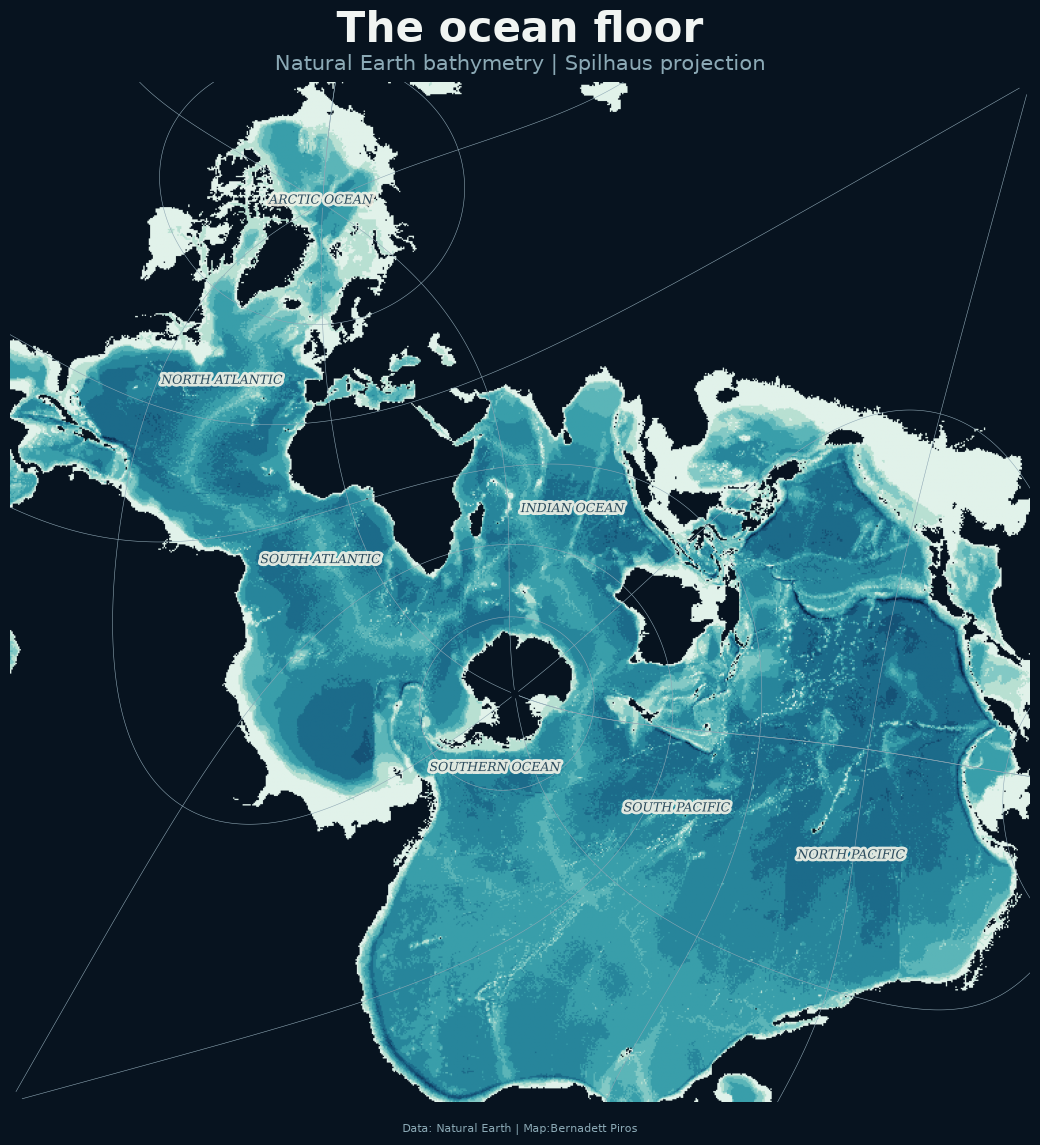

In [4]:
fig, ax = plt.subplots(figsize=(13, 12), subplot_kw={"projection": ccrs.Spilhaus()}, facecolor="#07131F")

# Bathymetry
ax.imshow(bathymetry, cmap=cmap, norm=norm, transform=ccrs.PlateCarree())

# Gridlines
ax.gridlines(crs=ccrs.PlateCarree(), draw_labels=False, color="#8FA8B5", lw=0.4, ls="-", zorder=2)

# Ocean labels 
oceans = {
    "NORTH PACIFIC": (-150, 30),
    "SOUTH PACIFIC": (-150, -20),
    "NORTH ATLANTIC": (-40, 40),
    "SOUTH ATLANTIC": (-15, -15),
    "INDIAN OCEAN": (85, -15),
    "ARCTIC OCEAN": (0, 90),
    "SOUTHERN OCEAN": (-95,-65)
}

for name, (lon, lat) in oceans.items():

    ax.text(lon, lat, name, transform=ccrs.PlateCarree(), color="#173B50", alpha=0.9,
            size=9, fontfamily="DejaVu Serif", fontstyle="italic", ha="center", zorder=5,
            path_effects=[path_effects.withStroke(linewidth=4, foreground="#F4F4E8")])

ax.set_facecolor("#EDF6EE")
ax.set_global()
ax.axis("off")

# Title
fig.text(0.5, 0.96,
         "The ocean floor",
         color="#F0F4F2", size=30, weight="bold", ha="center", va="top")

# Subtitle
fig.text(0.5, 0.91,
         "Natural Earth bathymetry | Spilhaus projection",
         color="#8BA9B5", size=15, ha="center")

# Caption
fig.text(0.5, 0.025,
         "Data: Natural Earth | Map:Bernadett Piros",
         color="#8BA9B5", size=8, ha="center")

plt.subplots_adjust(left=0.02, right=0.98, bottom=0.05, top=0.9)

plt.show()

#fig.savefig("water.png", bbox_inches="tight", pad_inches=0.2)